In [1]:
%load_ext autoreload
%autoreload 2

# Broad-scale characterstics of NPP limitation factors
This notebook plots a map of the primary limitation factor at each location.
- [x] Primary limitation (based on linear correlation)
- [ ] relation of PPP to growth limitation

In [2]:
import esm4ppe
import itertools
import xarray as xr
import glob
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib as mpl
from dask.diagnostics import ProgressBar
import numpy as np
from functions import *

In [3]:
weighted = True

In [4]:
phytotypes = {'diat':{'longname':'Diatoms'},
              'diaz':{'longname':'Diazotrophs'},
              'misc':{'longname':'Miscellaneous'},
              'pico':{'longname':'Picophytoplankton'}}
limitations = {'limfe':{'longname':'Iron',
                        'color':'tab:blue'},
               'limirr':{'longname':'Light',
                         'color':'tab:green'},
               'limn':{'longname':'Nitrate',
                       'color':'tab:orange'},
               'limp':{'longname':'Phosphate',
                       'color':'tab:red'}}

In [5]:
# load correlations
path = esm4ppe.sysconfig['correlationpathroot']+"/pearson.intpp*-lim*.bymonth.nc"
cr = xr.open_mfdataset(path)
# load static
static = esm4ppe.esm4ppeObj('intpp','monthly').static

Opening static... static opened.


/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


## Primary limitation

In [6]:
cr_m = xr.Dataset()
if weighted:
    # weighted mean correlation
    variables = cr.data_vars
    for phytotype in phytotypes.keys():
        # load intpp climatology
        ds = esm4ppe.esm4ppeObj('intpp'+phytotype,'monthly').add_control().climatology().control
        # subset variables for phytotype
        varsnow = [v for v in variables if phytotype in v]
        tmp = cr[varsnow].weighted(ds['intpp'+phytotype].fillna(0)).mean('month')
        cr_m = xr.merge([cr_m,tmp])

Opening static... static opened.
Control present in zarr store... opening...
control opened.
Opening climatology... climatology opened.
Opening static... static opened.
Control present in zarr store... opening...
control opened.
Opening climatology... climatology opened.


/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


Opening static... static opened.
Control present in zarr store... opening...
control opened.
Opening climatology... climatology opened.


/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


Opening static... static opened.
Control present in zarr store... opening...
control opened.
Opening climatology... climatology opened.


/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


In [7]:
maxlims,limnames = calc_maxlims_allphyto(cr_m,static)
limnames

{'diat': ['limfe', 'limirr', 'limn', 'limp'],
 'diaz': ['limfe', 'limirr', 'limp'],
 'pico': ['limfe', 'limirr', 'limn', 'limp'],
 'misc': ['limfe', 'limirr', 'limn', 'limp']}

In [8]:
with ProgressBar():
    maxlims = maxlims.compute()

[########################################] | 100% Completed | 1.72 sms


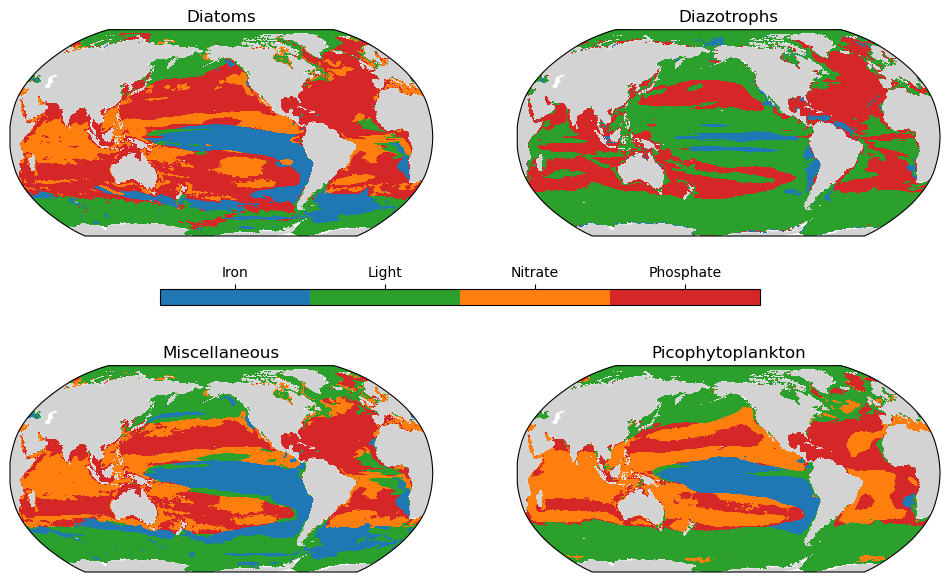

In [9]:
nph = len(phytotypes.keys())
nph2 = np.ceil(nph/2)
subplot_kw = {'projection':ccrs.Robinson(central_longitude=-150)}
fig,axarr = plt.subplots(figsize=(6*nph2,4*nph2),nrows=int(nph2),ncols=int(nph2),subplot_kw=subplot_kw)
for i,phytotype in enumerate(phytotypes.keys()):
    axnow = axarr.flat[i]
    da = maxlims[phytotype]+0.5
    limnamesnow = limnames[phytotype]
    colors = [limitations[l]['color'] for l in limnamesnow]
    longnames = [limitations[l]['longname'] for l in limnamesnow]
    cmap = mpl.colors.ListedColormap(colors)
    im,axnow = draw_globalplot_esm4(axnow,da,static,cmap=cmap)
    axnow.add_feature(cfeature.LAND,facecolor='lightgrey')
    im.set_clim([0,len(limnamesnow)])
    axnow.set_title(phytotypes[phytotype]['longname'])
axcb,imcb = add_colorbar(fig,im,[0.25,0.49,0.5,0.02])
imcb.set_ticks(np.arange(len(limnamesnow))+0.5)
imcb.set_ticklabels(longnames)
save_fig(fig,'fig.growthlimitation')

# Relationship to PPP

In [10]:
initmonth = 1

In [11]:
pppmean = xr.Dataset()
pppstd = xr.Dataset()
for phytotype,limitation in itertools.product(phytotypes.keys(),limitations.keys()):
    # Load ppp
    es = esm4ppe.esm4ppeObj('intpp'+phytotype,'monthly').verify('ppp',groupby='month')
    vs = es.vs.sel(month=initmonth)
    vs = vs.where(vs>0,0)
    try:
        limvalue = limnames[phytotype].index(limitation)
    except:
        continue
    name = limitation+phytotype
    # average ppp in each growth limit region
    pppmean[name] = (
        vs
        .where(maxlims[phytotype]==limvalue)
        .weighted(static['areacello'].fillna(0))
        .mean(["xh","yh"])
        ['intpp'+phytotype]
    )
    # standard deviations of ppp in each growth limit region
    pppstd[name] = (
        vs
        .where(maxlims[phytotype]==limvalue)
        .weighted(static['areacello'].fillna(0))
        .std(["xh","yh"])
        ['intpp'+phytotype]
    )

Opening static... static opened.
Opening skill metric... skill metric opened.


/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


Opening static... static opened.
Opening skill metric... skill metric opened.


/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


Opening static... static opened.
Opening skill metric... skill metric opened.


/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


... (20 outputs left out)

Opening static... static opened.
Opening skill metric... skill metric opened.


/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


Opening static... static opened.
Opening skill metric... skill metric opened.


/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


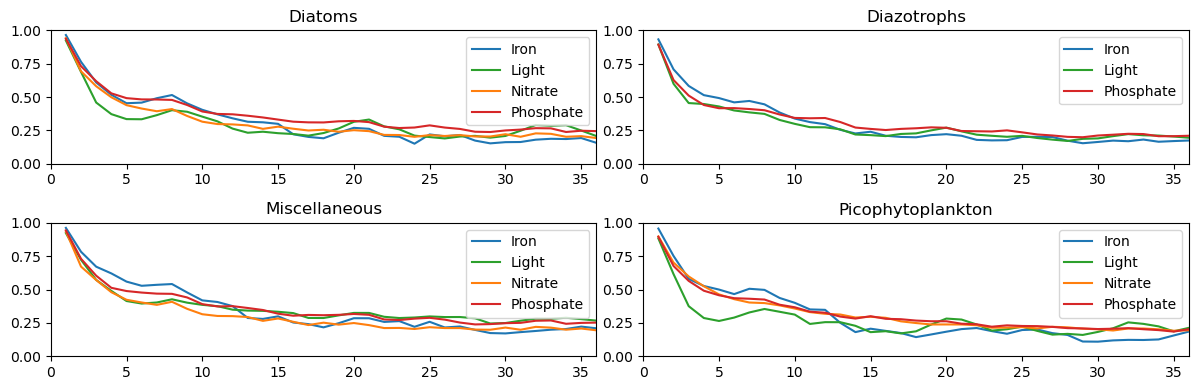

In [12]:
nph = len(phytotypes.keys())
nph2 = int(np.ceil(nph/2))
fig,axarr = plt.subplots(figsize=(6*nph2,2*nph2),nrows=nph2,ncols=2)
for i,phytotype in enumerate(phytotypes.keys()):
    axnow = axarr.flat[i]
    for limitation in limitations.keys():
        if (limitation=='limn') & (phytotype=='diaz'):
            continue
        name = limitation+phytotype
        color = limitations[limitation]['color']
        label = limitations[limitation]['longname']
        axnow.plot(pppmean['lead'],pppmean[name],color=color,label=label)
        # ylow = pppmean[name]-pppstd[name]
        # yhigh = pppmean[name]+pppstd[name]
        # axnow.fill_between(pppmean['lead'], ylow, yhigh, color=color, alpha=0.3)
    axnow.set_ylim([0,1])
    axnow.set_xlim([0,36])
    axnow.set_title(phytotypes[phytotype]['longname'])
    axnow.legend()
fig.tight_layout()

In [13]:
hs = xr.Dataset()
for phytotype,limitation in itertools.product(phytotypes.keys(),limitations.keys()):
    # Load ppp
    es = esm4ppe.esm4ppeObj('intpp'+phytotype,'monthly').verify('ppp',groupby='month')
    vs = es.vs.sel(month=initmonth)
    try:
        limvalue = limnames[phytotype].index(limitation)
    except:
        continue
    
    name = limitation+phytotype
    # propagate array of correlations out to full length of lead time
    # now histogram each lead time with the appropriate month
    crnow = cr['pearson_intpp'+phytotype+'-'+name]
    nlead = len(vs['lead'])
    montharray = np.tile(cr['month'].to_numpy(),int(nlead/12))
    crnow = crnow.sel(month=montharray).rename({'month':'lead'}).assign_coords({'lead':vs['lead']})
    
    # histogram
    bins = np.linspace(0,1,100)
    tmp = histogram(vs['intpp'+phytotype],
                    crnow,
                    bins=[bins,bins],
                    dim=['xh','yh'],
                    weights=es.static['areacello'],
                    density=True)
    hs[name] = tmp.rename({'intpp'+phytotype+'_bin':'skill','pearson_intpp'+phytotype+'-'+name+'_bin':'correlation'})

Opening static... static opened.
Opening skill metric... skill metric opened.


/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


Opening static... static opened.
Opening skill metric... skill metric opened.


/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


Opening static... static opened.
Opening skill metric... skill metric opened.


/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


... (20 outputs left out)

Opening static... static opened.
Opening skill metric... skill metric opened.


/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


Opening static... static opened.
Opening skill metric... skill metric opened.


/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


In [18]:
with ProgressBar():
    hsnow = hs['limirrdiat'].compute()

[########################################] | 100% Completed | 2.23 sms


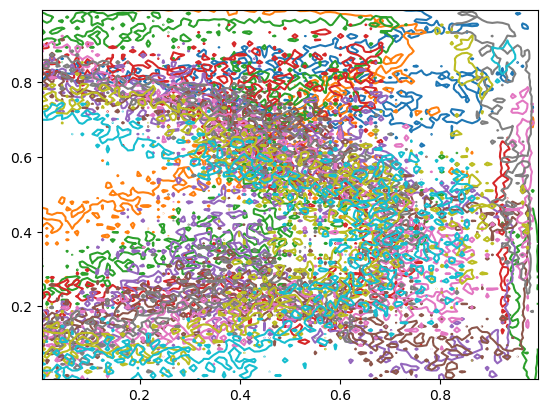

In [19]:
import matplotlib as mpl
colors = list(mpl.colors.TABLEAU_COLORS.keys())
leads=np.arange(1,11)
for lead in leads:
    plt.contour(hsnow['correlation'],hsnow['skill'],hsnow.sel(lead=lead),levels=[1],colors=colors[lead-1])

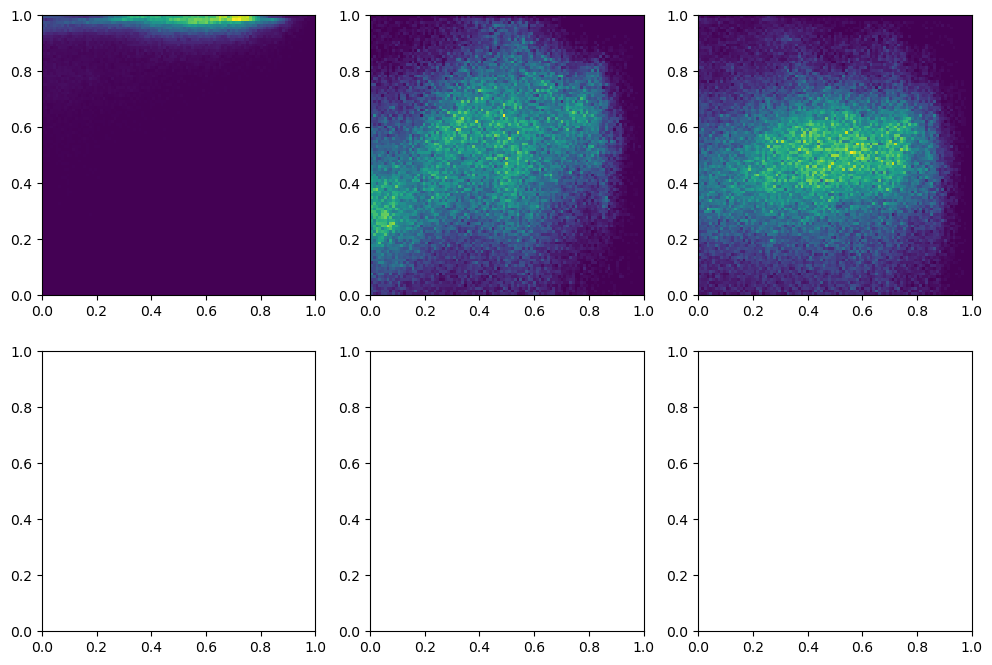

In [17]:
fig,ax = plt.subplots(figsize=(3*4,2*4),nrows=2,ncols=3)
ax[0,0].pcolormesh(hsnow['correlation'],hsnow['skill'],hsnow.sel(lead=1))
ax[0,1].pcolormesh(hsnow['correlation'],hsnow['skill'],hsnow.sel(lead=5))
ax[0,2].pcolormesh(hsnow['correlation'],hsnow['skill'],hsnow.sel(lead=9))